In [2]:
# NIM: 202531075

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from zipfile import ZipFile

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, KBinsDiscretizer
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
# NIM: 202531075

df = pd.read_csv("04_bank_customers.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
# NIM: 202531075

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [5]:
# NIM: 202531075

pd.DataFrame({
    "kosong": df.isna().sum(),
    "unknown": (df == "unknown").sum()
})

,kosong,unknown
age,0,0
job,0,288
marital,0,0
education,0,1857
default,0,0
balance,0,0
housing,0,0
loan,0,0
contact,0,13020
day,0,0


In [6]:
# NIM: 202531075

df.duplicated().sum()

np.int64(0)

In [7]:
# NIM: 202531075

df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


In [8]:
# NIM: 202531075

jumlah = df["y"].value_counts()

pd.DataFrame({
    "jumlah": jumlah,
    "persentase": (jumlah / len(df) * 100).round(2)
})

,jumlah,persentase
y,,
no,39922,88.3
yes,5289,11.7


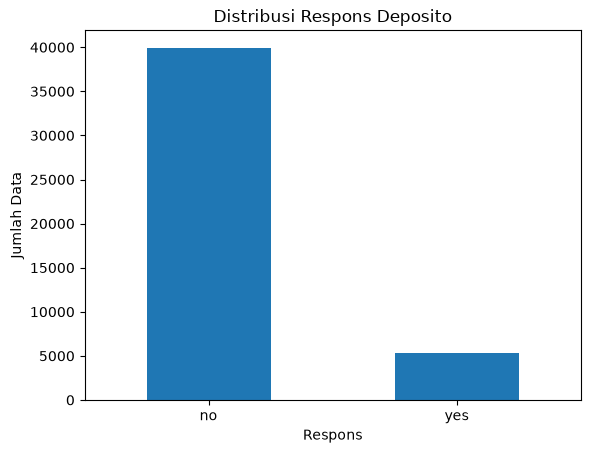

In [9]:
# NIM: 202531075

jumlah.plot(kind="bar", rot=0)

plt.title("Distribusi Respons Deposito")
plt.xlabel("Respons")
plt.ylabel("Jumlah Data")
plt.show()

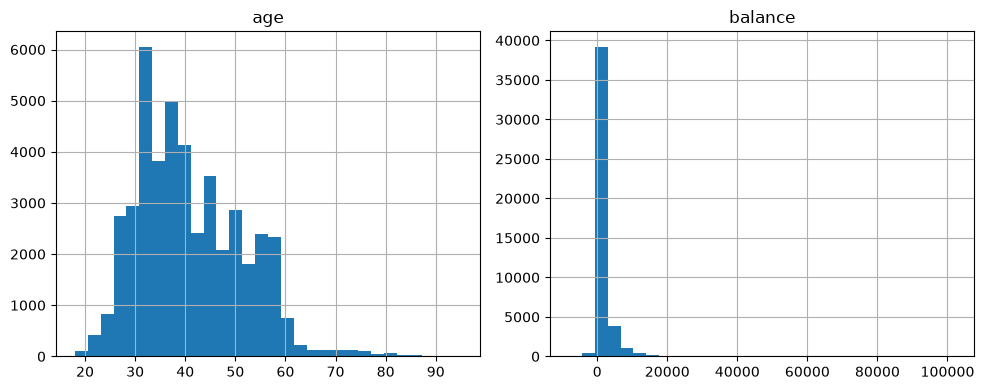

In [10]:
# NIM: 202531075

df[["age", "balance"]].hist(bins=30, figsize=(10, 4))

plt.tight_layout()
plt.show()

In [11]:
# NIM: 202531075

latih, uji = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["y"]
)

pd.DataFrame({
    "jumlah_data": [len(latih), len(uji)]
}, index=["Latih", "Uji"])

,jumlah_data
Latih,36168
Uji,9043


In [12]:
# NIM: 202531075

X_latih_reg = latih.drop(columns=["balance", "y", "duration"])
X_uji_reg = uji.drop(columns=["balance", "y", "duration"])

y_latih_reg = latih["balance"]
y_uji_reg = uji["balance"]

X_latih_reg = pd.get_dummies(X_latih_reg, drop_first=True, dtype=int)
X_uji_reg = pd.get_dummies(X_uji_reg, dtype=int)

X_uji_reg = X_uji_reg.reindex(
    columns=X_latih_reg.columns,
    fill_value=0
)

X_latih_reg.head()

,age,day,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
24001,36,29,2,-1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
43409,24,5,4,185,7,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20669,44,12,4,-1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
18810,48,31,11,-1,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
23130,38,26,10,-1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [13]:
# NIM: 202531075

model_reg = LinearRegression()
model_reg.fit(X_latih_reg, y_latih_reg)

prediksi_reg = model_reg.predict(X_uji_reg)

hasil_reg = pd.DataFrame({
    "saldo_asli": y_uji_reg,
    "saldo_prediksi": prediksi_reg
})

hasil_reg.head(10).round(2)

,saldo_asli,saldo_prediksi
1392,640,360.62
7518,378,1171.69
12007,356,1104.18
5536,655,844.26
29816,1921,950.71
18275,1138,1328.01
8543,2589,2116.86
43965,109,2203.58
28083,1803,428.66
25787,2279,2038.30


In [14]:
# NIM: 202531075

mae = mean_absolute_error(y_uji_reg, prediksi_reg)
rmse = np.sqrt(mean_squared_error(y_uji_reg, prediksi_reg))
r2 = r2_score(y_uji_reg, prediksi_reg)

pd.DataFrame({
    "MAE": [mae],
    "RMSE": [rmse],
    "R2": [r2]
}).round(4)

,MAE,RMSE,R2
0,1486.6654,2868.3408,0.0531


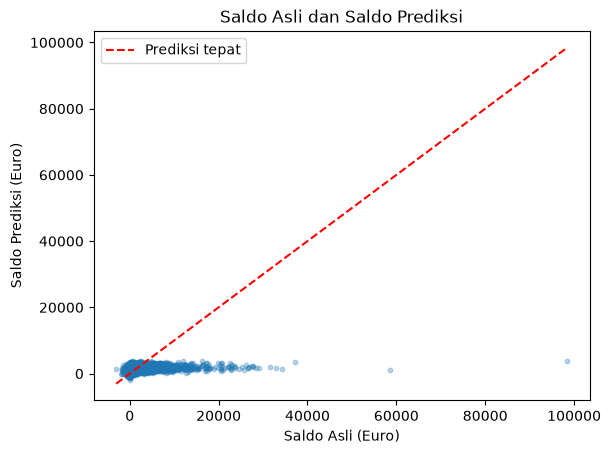

In [15]:
# NIM: 202531075

plt.scatter(y_uji_reg, prediksi_reg, alpha=0.3, s=10)

batas = [y_uji_reg.min(), y_uji_reg.max()]
plt.plot(batas, batas, "r--", label="Prediksi tepat")

plt.title("Saldo Asli dan Saldo Prediksi")
plt.xlabel("Saldo Asli (Euro)")
plt.ylabel("Saldo Prediksi (Euro)")
plt.legend()
plt.show()

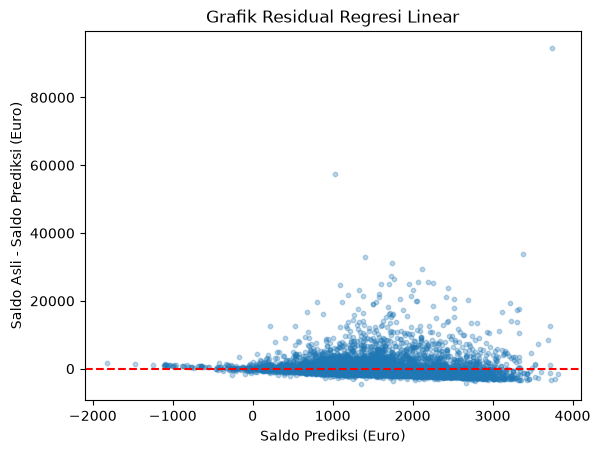

In [16]:
# NIM: 202531075

residual = y_uji_reg - prediksi_reg

plt.scatter(prediksi_reg, residual, alpha=0.3, s=10)
plt.axhline(0, color="red", linestyle="--")

plt.title("Grafik Residual Regresi Linear")
plt.xlabel("Saldo Prediksi (Euro)")
plt.ylabel("Saldo Asli - Saldo Prediksi (Euro)")
plt.show()

In [17]:
# NIM: 202531075

X_latih_nb = latih.drop(columns=["y", "duration"])
X_uji_nb = uji.drop(columns=["y", "duration"])

y_latih_nb = latih["y"]
y_uji_nb = uji["y"]

X_latih_nb.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
24001,36,technician,divorced,secondary,no,861,no,no,telephone,29,aug,2,-1,0,unknown
43409,24,student,single,secondary,no,4126,no,no,cellular,5,apr,4,185,7,failure
20669,44,technician,single,secondary,no,244,yes,no,cellular,12,aug,4,-1,0,unknown
18810,48,unemployed,married,secondary,no,0,no,no,telephone,31,jul,11,-1,0,unknown
23130,38,technician,married,secondary,no,257,no,no,cellular,26,aug,10,-1,0,unknown


In [18]:
# NIM: 202531075

kolom_angka = ["age", "balance"]

pembagi = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile",
    quantile_method="averaged_inverted_cdf"
)

angka_latih = pembagi.fit_transform(
    X_latih_nb[kolom_angka]
).astype(int)

angka_uji = pembagi.transform(
    X_uji_nb[kolom_angka]
).astype(int)

pd.DataFrame(angka_latih, columns=kolom_angka).head()

,age,balance
0,2,3
1,0,4
2,3,1
3,3,0
4,2,1


In [19]:
# NIM: 202531075

kolom_kategori = X_latih_nb.columns.difference(kolom_angka)

pengkode = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

kategori_latih = pengkode.fit_transform(
    X_latih_nb[kolom_kategori].astype(str)
).astype(int) + 1

kategori_uji = pengkode.transform(
    X_uji_nb[kolom_kategori].astype(str)
).astype(int) + 1

pd.DataFrame(kategori_latih, columns=kolom_kategori).head()

,campaign,contact,day,default,education,housing,job,loan,marital,month,pdays,poutcome,previous
0,12,2,22,1,2,1,10,1,1,2,1,4,1
1,34,1,27,1,2,1,9,1,3,1,94,1,39
2,34,1,4,1,2,2,10,1,3,2,1,4,1
3,3,2,25,1,2,1,11,1,2,6,1,4,1
4,2,1,19,1,2,1,10,1,2,2,1,4,1


In [20]:
# NIM: 202531075

X_latih_nb_akhir = np.column_stack([angka_latih, kategori_latih])
X_uji_nb_akhir = np.column_stack([angka_uji, kategori_uji])

model_nb = CategoricalNB()
model_nb.fit(X_latih_nb_akhir, y_latih_nb)

prediksi_nb = model_nb.predict(X_uji_nb_akhir)

hasil_nb = pd.DataFrame({
    "respons_asli": y_uji_nb,
    "respons_prediksi": prediksi_nb
})

hasil_nb.head(10)

,respons_asli,respons_prediksi
1392,no,no
7518,no,no
12007,no,no
5536,no,no
29816,no,no
18275,no,no
8543,no,no
43965,yes,yes
28083,no,no
25787,no,no


In [21]:
# NIM: 202531075

akurasi = accuracy_score(y_uji_nb, prediksi_nb)

print("Akurasi:", round(akurasi * 100, 2), "%")
print(classification_report(y_uji_nb, prediksi_nb, zero_division=0))

Akurasi: 86.83 %
              precision    recall  f1-score   support

          no       0.92      0.93      0.93      7985
         yes       0.43      0.38      0.40      1058

    accuracy                           0.87      9043
   macro avg       0.67      0.66      0.66      9043
weighted avg       0.86      0.87      0.86      9043



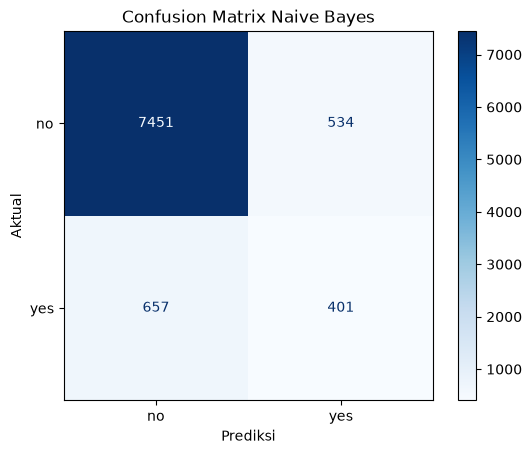

In [22]:
# NIM: 202531075

ConfusionMatrixDisplay.from_predictions(
    y_uji_nb,
    prediksi_nb,
    labels=["no", "yes"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix Naive Bayes")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()